# Reproducibility of Numerical Results and Figures in Manuscript

**Paper:** A. J. Aw, *Semi-regular admixed arrays: asymptotic enumeration and when information is additive*.

This notebook regenerates every computed value and data figure in the manuscript and checks each against the value printed in the paper. 

- Computed values are checked against both combinatorial formulae and functions from `zagar` (v0.2.0), our accompanying package.
- Figures 1 and 2 are schemas while Figure 3 comes from our mathematical results. Thus we provide code to reproduce Figure 3 only. 

| Section | Manuscript item |
|---|---|
| 1 | Example 2.1: $|\mathscr A_1|$, $|\mathscr A_2|$, $|\mathscr S|$, $|\mathscr A_{12}|$ |
| 2 | Constants in the Introduction and Discussion |
| 3 | Figure 3 (where the independence heuristic holds) |
| 4 | The values in the caption of Figure 3 |

Figures 1 and 2 are schematic diagrams with no computed content.

**Requirements:** `zagar` ≥ 0.2.0, `numpy`, `scipy`, `matplotlib`; LaTeX with `pgfplots` ≥ 1.18 for the publication version of Figure 3. Run all cells from top to bottom; the notebook takes about a minute.

In [1]:
import itertools, math, os, subprocess, sys, shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import zagar

ROOT = Path.cwd()
FIG3 = ROOT / "figure3"
sys.path.insert(0, str(FIG3))          # tested helper modules for Figure 3

checks = []                             # (item, computed, paper value, passed)
def check(item, computed, paper):
    checks.append((item, computed, paper, computed == paper))

def show(rows, header=("Quantity", "Computed", "Paper", "")):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

print("zagar", zagar.__version__, "| numpy", np.__version__, "| python", sys.version.split()[0])

zagar 0.2.0 | numpy 1.26.1 | python 3.12.0


## 1. Example 2.1

The two-way diploid example has $N=3$ individuals, $P=4$ loci, local ancestry tallies $\mathbf a=(6,1,7)$ and ancestry-specific sums $\boldsymbol\phi_0=(2,0,2,1)$, $\boldsymbol\phi_1=(1,3,4,1)$.
Proposition 2.3 gives

$$|\mathscr A_1| = 2^{2NP}\prod_{n}\binom{2P}{a_n},\qquad
|\mathscr A_2| = \prod_p \binom{2N}{\phi_{p0}+\phi_{p1}}\binom{\phi_{p0}+\phi_{p1}}{\phi_{p1}}\,2^{2N-\phi_{p0}-\phi_{p1}},$$

and $|\mathscr A_{12}|$ as a sum over the feasible set $\mathscr S$ of Eq. (2.4). We compute $|\mathscr A_{12}|$ three independent ways: by evaluating Eq. (2.3) directly here, and with the two exact algorithms in `zagar`, which share no code.

In [2]:
N, P = 3, 4
a, phi0, phi1 = [6, 1, 7], [2, 0, 2, 1], [1, 3, 4, 1]

A1 = 2 ** (2 * N * P) * math.prod(math.comb(2 * P, x) for x in a)
A2 = math.prod(math.comb(2 * N, p0 + p1) * math.comb(p0 + p1, p1) * 2 ** (2 * N - p0 - p1)
               for p0, p1 in zip(phi0, phi1))

# Feasible set S (Eq. 2.4), locus by locus: phi1 <= v1 + v2 <= 2N - phi0
per_locus = [[(x, y) for x in range(N + 1) for y in range(N + 1) if p1 <= x + y <= 2 * N - p0]
             for p0, p1 in zip(phi0, phi1)]
S_size = math.prod(len(c) for c in per_locus)

# |A12| by Eq. (2.3): sum over S of |A(s1, s2, a)| times the binomial weights
A12_eq23 = 0
for choice in itertools.product(*per_locus):
    w = math.prod(math.comb(x + y, p1) * math.comb(2 * N - x - y, p0)
                  for (x, y), p0, p1 in zip(choice, phi0, phi1))
    if w:
        A12_eq23 += w * zagar.count_matrices(a, [c[0] for c in choice] + [c[1] for c in choice])
A12_dp = int(zagar.count_A12(N, a, phi0, phi1, method="dp"))
A12_cs = int(zagar.count_A12(N, a, phi0, phi1, method="column-sums"))

rows = [("|A1|  (Eq. 2.1)", A1, 30_064_771_072),
        ("|A1|  (zagar.getA1)", int(zagar.getA1(N, P, a)), 30_064_771_072),
        ("|A2|  (Eq. 2.2)", A2, 552_960_000),
        ("|A2|  (zagar.getA2)", int(zagar.getA2(N, P, phi0, phi1)), 552_960_000),
        ("|S|   (Eq. 2.4)", S_size, 5_040),
        ("|A12| (Eq. 2.3, sum over S)", A12_eq23, 133_520),
        ("|A12| (zagar, dynamic programming)", A12_dp, 133_520),
        ("|A12| (zagar, column-sum enumeration)", A12_cs, 133_520)]
for r in rows: check(*r)
show([(q, f"{c:,}", f"{p:,}", "✓" if c == p else "✗") for q, c, p in rows])

| Quantity | Computed | Paper |  |
|---|---|---|---|
| |A1|  (Eq. 2.1) | 30,064,771,072 | 30,064,771,072 | ✓ |
| |A1|  (zagar.getA1) | 30,064,771,072 | 30,064,771,072 | ✓ |
| |A2|  (Eq. 2.2) | 552,960,000 | 552,960,000 | ✓ |
| |A2|  (zagar.getA2) | 552,960,000 | 552,960,000 | ✓ |
| |S|   (Eq. 2.4) | 5,040 | 5,040 | ✓ |
| |A12| (Eq. 2.3, sum over S) | 133,520 | 133,520 | ✓ |
| |A12| (zagar, dynamic programming) | 133,520 | 133,520 | ✓ |
| |A12| (zagar, column-sum enumeration) | 133,520 | 133,520 | ✓ |

## 2. Constants in the Introduction and Discussion

* **Introduction.** A correction factor $e^{-1/4}$ (respectively $e^{-1/2}$) means the doubly constrained event carries $1/(4\ln 2)$ (respectively $1/(2\ln 2)$) bits more than the two constraint events separately.
* **Discussion.** At fixed $N$ and $P$, additivity to within one bit requires $|\mathcal L| < 1/(2NP)$; the paper evaluates this at $N=10^4$ individuals and $P=10^6$ loci.

In [3]:
rows = [("1/(4 ln 2) bits", f"{1 / (4 * math.log(2)):.2f}", "0.36"),
        ("1/(2 ln 2) bits", f"{1 / (2 * math.log(2)):.2f}", "0.72"),
        ("1/(2NP), N=1e4, P=1e6", f"{1 / (2 * 10**4 * 10**6):.0e}", "5e-11")]
for r in rows: check(*r)
show([(q, c, p, "✓" if c == p else "✗") for q, c, p in rows])

| Quantity | Computed | Paper |  |
|---|---|---|---|
| 1/(4 ln 2) bits | 0.36 | 0.36 | ✓ |
| 1/(2 ln 2) bits | 0.72 | 0.72 | ✓ |
| 1/(2NP), N=1e4, P=1e6 | 5e-11 | 5e-11 | ✓ |

## 3. Figure 3

Figure 3 shows where the independence heuristic holds. Panels (a)–(c) are slices of the feasible region at fixed $\bar a$, shaded by the sign of the entropy gap

$$\mathcal L(\bar a,f_0,f_1)=\mathcal H(\bar a,f_0,f_1)+H(\bar a_{\mathscr V},1-\bar a_{\mathscr V})-H(\bar a,1-\bar a)-H(f_0,f_1,1-f_0-f_1)-(1-f_0-f_1).$$

Panel (d) is the Case 2 face $f_1=\bar a$, where $\mathcal L=0$ reduces to $\varphi(\bar a)=\varphi(1-f_0)$ with $\varphi(x)=H(x,1-x)-x$.

The formulas are in `figure3/common.py`. `figure3/export3.py` evaluates them and writes the curves and regions to `figure3/tikz3/data/`; `figure3/make3.py` writes the TikZ code. The cell below runs both, compiles the publication PDF if LaTeX is available, and confirms that the regenerated data match the files shipped with the paper.

In [4]:
shipped = {f.name: f.read_bytes() for f in (FIG3 / "tikz3" / "data").glob("*.dat")}

run = lambda *cmd, cwd=FIG3: subprocess.run(cmd, cwd=cwd, check=True, capture_output=True, text=True)
run(sys.executable, "export3.py")
run(sys.executable, "make3.py")

if shipped:
    same = all((FIG3 / "tikz3" / "data" / k).read_bytes() == v for k, v in shipped.items())
    check("Figure 3 data regenerated identically", same, True)
    print(f"Regenerated data identical to the {len(shipped)} shipped files:", same)
else:
    print("No shipped data files found to compare against; regenerated them from scratch.")

if shutil.which("pdflatex"):
    run("pdflatex", "-interaction=nonstopmode", "fig_kappa_region.tex", cwd=FIG3 / "tikz3")
    print("Publication figure written to figure3/tikz3/fig_kappa_region.pdf")
else:
    print("pdflatex not found: skipping the TikZ build (the preview below does not need it).")

Regenerated data identical to the 8 shipped files: True
Publication figure written to figure3/tikz3/fig_kappa_region.pdf


The publication figure is typeset with TikZ/pgfplots. For a quick look, the next cell draws the same data with matplotlib. The colours and markers match the paper; the legend of the PDF explains them.

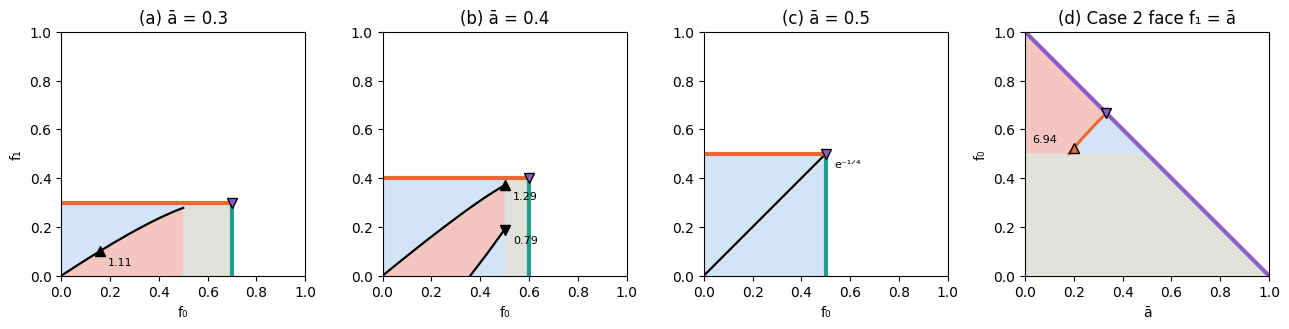

In [5]:
import json
D = FIG3 / "tikz3" / "data"
meta = json.load(open(FIG3 / "tikz3" / "meta.json"))

def read_segments(path):
    segs, cur = [], []
    for line in open(path):
        if line.strip():
            cur.append(tuple(map(float, line.split())))
        elif cur:
            segs.append(np.array(cur)); cur = []
    if cur: segs.append(np.array(cur))
    return segs

POS, NEG, OUT = "#F3C6C0", "#D3E3F8", "#E2E2DC"
C2, C3, C4 = "#EB6834", "#1F9E89", "#8C5CC7"
case_col = {1: "black", 2: C2, 3: C3, 4: C4}

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, tag, lab in zip(axes[:3], ["30", "40", "50"], "abc"):
    m = meta[tag]; f0m, f1m = m["f0max"], m["f1max"]
    ax.add_patch(plt.Rectangle((0, 0), m["X0"], m["X1"], color=NEG, lw=0))
    for s in read_segments(D / f"pos_{tag}.dat"):
        ax.fill(s[:, 0], s[:, 1], color=POS, lw=0)
    if f0m > .5: ax.add_patch(plt.Rectangle((.5, 0), f0m - .5, f1m, color=OUT, lw=0))
    if f1m > .5: ax.add_patch(plt.Rectangle((0, .5), f0m, f1m - .5, color=OUT, lw=0))
    for s in read_segments(D / f"zero_{tag}.dat"):
        ax.plot(s[:, 0], s[:, 1], "k", lw=1.6)
    ax.plot([0, f0m], [f1m, f1m], color=C2, lw=3); ax.plot([f0m, f0m], [0, f1m], color=C3, lw=3)
    for x, y, k, case, text, _ in m["marks"]:
        ax.plot(x, y, "^" if k > 1 else "v", ms=7, mfc=case_col[case], mec="k", zorder=5)
        if text: ax.annotate(text.replace("$", "").replace("e^{-1/4}", "e⁻¹ᐟ⁴"), (x, y),
                             textcoords="offset points", xytext=(6, -10), fontsize=8)
    ax.set(title=f"({lab}) ā = {m['a']}", xlabel="f₀", xlim=(0, 1), ylim=(0, 1), aspect="equal")
axes[0].set_ylabel("f₁")

ax = axes[3]
ax.fill([0, 1, .5, 0], [0, 0, .5, .5], color=OUT, lw=0)
ax.fill([0, .5, 0], [.5, .5, 1], color=NEG, lw=0)
for s in read_segments(D / "face_pos.dat"):
    ax.fill(s[:, 0], s[:, 1], color=POS, lw=0)
ax.plot([0, 1], [1, 0], color=C4, lw=3)
for s in read_segments(D / "face_curve.dat"):
    ax.plot(s[:, 0], s[:, 1], color=C2, lw=2.2)
ex = meta["face"]["ex"]
ax.plot(ex[0], ex[1], "^", ms=7, mfc=C2, mec="k", zorder=5)
ax.annotate(f"{ex[2]:.2f}", ex[:2], textcoords="offset points", xytext=(-30, 4), fontsize=8)
ax.plot(1/3, 2/3, "v", ms=7, mfc=C4, mec="k", zorder=5)
ax.set(title="(d) Case 2 face f₁ = ā", xlabel="ā", ylabel="f₀", xlim=(0, 1), ylim=(0, 1), aspect="equal")
plt.tight_layout(); plt.show()

## 4. Values in the caption of Figure 3

The caption reports the limit of $\kappa_{N,P}=|\mathscr A_{12}|\,|\mathscr V|/(|\mathscr A_1|\,|\mathscr A_2|)$ at points where the heuristic holds. We check each value two ways:

1. **Closed form**, from Proposition 4.3 and Corollaries 4.1 and 4.4: $\kappa_\eta=\eta^{-1/2}e^{-(1-\eta)/4}$ in Case 1, halved on the plane $f_0=1/2$; $e^{-1/4}\sqrt{4\pi\bar a(1-\bar a)}\,C_{\mathscr V}$ in Case 2; $e^{-1/4}$ in Case 4.
2. **Finite size**, using `zagar.log2_A12_asymptotic` (Theorem 3.4) for $|\mathscr A_{12}|$ and the exact formulas for $|\mathscr A_1|$, $|\mathscr A_2|$ and $|\mathscr V|$, at $N=P$ up to 3200. These should converge to the closed form.

The Case 1 and Case 2 points lie on $\mathcal L=0$ at irrational densities, so the binomial coefficients are evaluated with the Gamma function; the helper module checks that this agrees with `zagar.getA1` and `zagar.getA2` at integer inputs. The functions are in `figure3/reproduce_fig3_caption.py`.

In [6]:
import reproduce_fig3_caption as cap
cap.check_real_argument_formulas()

sizes = [50, 200, 800, 3200]
results = []
for name, (ab, f0, f1), caption in cap.caption_points():
    limit = cap.limit_closed_form(ab, f0, f1)
    kappas = [cap.kappa_NP(n, n, ab, f0, f1) for n in sizes]
    paper = math.exp(-0.25) if caption == "e^{-1/4}" else float(caption)
    results.append((name, (ab, f0, f1), caption, kappas, limit))
    check(f"Fig. 3 caption {name} {caption}", round(limit, 2), round(paper, 2))

show([(n, f"({ab:.2f}, {f0:.4f}, {f1:.4f})", *[f"{k:.4f}" for k in ks], f"{lim:.4f}", c.replace("e^{-1/4}", "e^(−1/4)"))
      for n, (ab, f0, f1), c, ks, lim in results],
     header=("Point", "(ā, f₀, f₁)", *[f"N=P={n}" for n in sizes], "Limit", "Caption"))

Gamma-function |A1|, |A2| agree with zagar.getA1 / zagar.getA2 at integer inputs.



| Point | (ā, f₀, f₁) | N=P=50 | N=P=200 | N=P=800 | N=P=3200 | Limit | Caption |
|---|---|---|---|---|---|---|---|
| (a) Case 1, L=0 | (0.30, 0.1569, 0.1000) | 1.1140 | 1.1117 | 1.1111 | 1.1110 | 1.1109 | 1.11 |
| (b) Case 1, f0=1/2 | (0.40, 0.5000, 0.1894) | 0.8006 | 0.7898 | 0.7871 | 0.7864 | 0.7862 | 0.79 |
| (b) Case 1, f0=1/2 | (0.40, 0.5000, 0.3703) | 1.3170 | 1.2980 | 1.2931 | 1.2919 | 1.2915 | 1.29 |
| (d) Case 2, L=0 | (0.20, 0.5235, 0.2000) | 6.5222 | 6.9206 | 6.9421 | 6.9410 | 6.9401 | 6.94 |
| Case 4 edge | (0.30, 0.7000, 0.3000) | 0.7865 | 0.7807 | 0.7793 | 0.7789 | 0.7788 | e^(−1/4) |
| Case 4 edge | (0.40, 0.6000, 0.4000) | 0.7865 | 0.7807 | 0.7793 | 0.7789 | 0.7788 | e^(−1/4) |
| Case 4 edge | (0.50, 0.5000, 0.5000) | 0.7865 | 0.7807 | 0.7793 | 0.7789 | 0.7788 | e^(−1/4) |

The relative error of $\kappa_{N,P}$ against its limit falls roughly like $1/N$ (dashed line). For the Case 2 point, $\kappa_{N,P}$ starts below its limit and crosses it between $N=P=200$ and $800$, so its error dips there before settling.

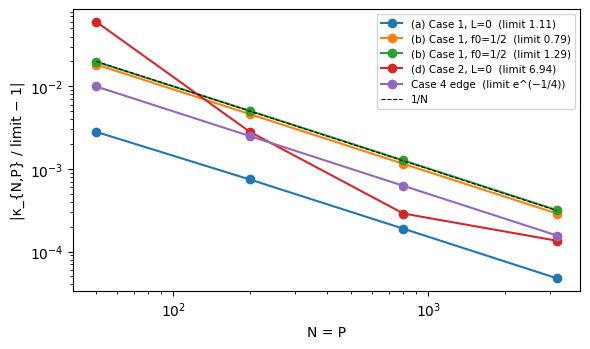

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.6))
seen = set()
for name, pt, c, ks, lim in results:
    if name == "Case 4 edge" and name in seen:
        continue                                   # the three Case 4 points coincide
    seen.add(name)
    lbl = f"{name}  (limit {lim:.2f})" if name != "Case 4 edge" else "Case 4 edge  (limit e^(−1/4))"
    ax.loglog(sizes, [abs(k / lim - 1) for k in ks], "o-", label=lbl)
ax.loglog(sizes, [1 / n for n in sizes], "k--", lw=0.8, label="1/N")
ax.set(xlabel="N = P", ylabel="|κ_{N,P} / limit − 1|")
ax.legend(fontsize=7.5); plt.tight_layout(); plt.show()

## Summary

In [8]:
show([(i, c, p, "✓" if ok else "✗") for i, c, p, ok in checks], header=("Check", "Computed", "Paper", ""))
assert all(ok for *_, ok in checks), "Some values do not match the manuscript."
print(f"All {len(checks)} checks passed.")

| Check | Computed | Paper |  |
|---|---|---|---|
| |A1|  (Eq. 2.1) | 30064771072 | 30064771072 | ✓ |
| |A1|  (zagar.getA1) | 30064771072 | 30064771072 | ✓ |
| |A2|  (Eq. 2.2) | 552960000 | 552960000 | ✓ |
| |A2|  (zagar.getA2) | 552960000 | 552960000 | ✓ |
| |S|   (Eq. 2.4) | 5040 | 5040 | ✓ |
| |A12| (Eq. 2.3, sum over S) | 133520 | 133520 | ✓ |
| |A12| (zagar, dynamic programming) | 133520 | 133520 | ✓ |
| |A12| (zagar, column-sum enumeration) | 133520 | 133520 | ✓ |
| 1/(4 ln 2) bits | 0.36 | 0.36 | ✓ |
| 1/(2 ln 2) bits | 0.72 | 0.72 | ✓ |
| 1/(2NP), N=1e4, P=1e6 | 5e-11 | 5e-11 | ✓ |
| Figure 3 data regenerated identically | True | True | ✓ |
| Fig. 3 caption (a) Case 1, L=0 1.11 | 1.11 | 1.11 | ✓ |
| Fig. 3 caption (b) Case 1, f0=1/2 0.79 | 0.79 | 0.79 | ✓ |
| Fig. 3 caption (b) Case 1, f0=1/2 1.29 | 1.29 | 1.29 | ✓ |
| Fig. 3 caption (d) Case 2, L=0 6.94 | 6.94 | 6.94 | ✓ |
| Fig. 3 caption Case 4 edge e^{-1/4} | 0.78 | 0.78 | ✓ |
| Fig. 3 caption Case 4 edge e^{-1/4} | 0.78 | 0.78 | ✓ |
| Fig. 3 caption Case 4 edge e^{-1/4} | 0.78 | 0.78 | ✓ |

All 19 checks passed.
